# Prediksi Customer Churn Menggunakan K-Nearest Neighbors (KNN)
### Pendekatan Alternatif: One-Hot Encoding, Seleksi Fitur Korelasi Pearson, dan Eksperimen Nilai K (3, 5, 7, 9)

**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)  
**Metodologi:** CRISP-DM (Cross-Industry Standard Process for Data Mining)


## 1. Atur Lokasi File Dataset


In [1]:
import os

FOLDER_DATA = 'data'
NAMA_FILE = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
LOKASI_FILE = os.path.join(FOLDER_DATA, NAMA_FILE)

# Cek apakah file ditemukan
if os.path.exists(LOKASI_FILE):
    print(f'File dataset ditemukan di: {LOKASI_FILE}')
else:
    print(f'File TIDAK ditemukan: {LOKASI_FILE}')


File dataset ditemukan di: data\WA_Fn-UseC_-Telco-Customer-Churn.csv


## 2. Import Library yang Dibutuhkan


In [2]:
# Library manipulasi data & visualisasi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Library Machine Learning (Scikit-Learn)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print('Semua library berhasil diimport!')


Semua library berhasil diimport!


---
## FASE 1: Business Understanding

### 1.1 Latar Belakang & Masalah
*Customer churn* adalah fenomena di mana pelanggan berhenti berlangganan atau berpindah ke kompetitor. Biaya untuk mengakuisisi pelanggan baru (*customer acquisition cost*) jauh lebih mahal daripada mempertahankan pelanggan lama.

### 1.2 Tujuan
1. Menganalisis faktor-faktor yang paling mempengaruhi *churn* menggunakan **Korelasi Pearson**.
2. Melakukan transformasi data kategorikal menggunakan **One-Hot Encoding**.
3. Mempertahankan skala fitur secara adil menggunakan **Normalisasi Min-Max**.
4. Mengembangkan dan membandingkan performa model **K-Nearest Neighbors (KNN)** dengan berbagai nilai $K \in \{3, 5, 7, 9\}$.


---
## FASE 2: Data Understanding

### 2.1 Load Dataset & Eksplorasi Awal


In [3]:
# Baca dataset
dataset = pd.read_csv(LOKASI_FILE)

print('Dataset berhasil dimuat!')
print(f'Jumlah Baris : {dataset.shape[0]}')
print(f'Jumlah Kolom : {dataset.shape[1]}')
dataset.head()


Dataset berhasil dimuat!
Jumlah Baris : 7043
Jumlah Kolom : 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Informasi tipe data dan struktur awal
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 2.2 Distribusi Target (Churn)


Distribusi Churn:
No  (Tidak Churn) : 5174 (73.5%)
Yes (Churn)       : 1869 (26.5%)


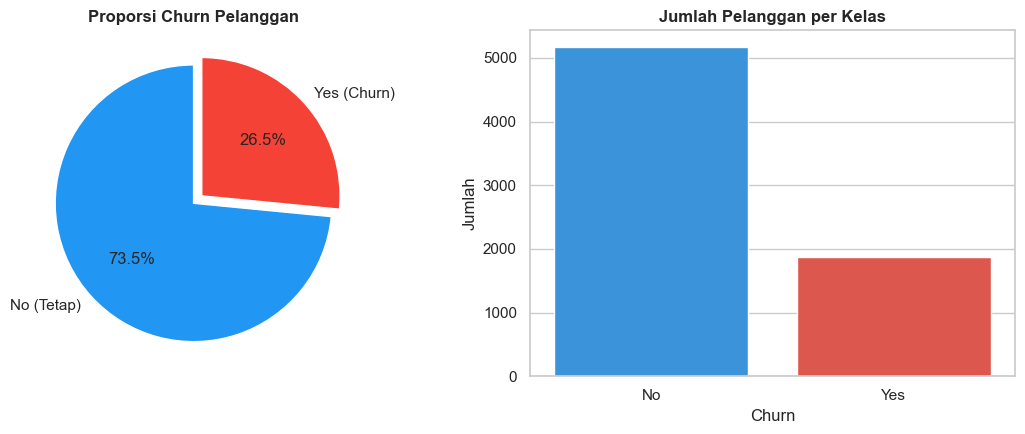

In [5]:
# Hitung proporsi kelas target
distribusi_churn = dataset['Churn'].value_counts()
persentase_churn = dataset['Churn'].value_counts(normalize=True) * 100

print('Distribusi Churn:')
print(f'No  (Tidak Churn) : {distribusi_churn["No"]} ({persentase_churn["No"]:.1f}%)')
print(f'Yes (Churn)       : {distribusi_churn["Yes"]} ({persentase_churn["Yes"]:.1f}%)')

# Visualisasi distribusi target
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# Donut chart
ax[0].pie(distribusi_churn, labels=['No (Tetap)', 'Yes (Churn)'], autopct='%1.1f%%',
          colors=['#2196F3', '#F44336'], startangle=90, explode=[0, 0.08])
ax[0].set_title('Proporsi Churn Pelanggan', fontsize=12, fontweight='bold')

# Bar chart
sns.countplot(data=dataset, x='Churn', palette=['#2196F3', '#F44336'], ax=ax[1])
ax[1].set_title('Jumlah Pelanggan per Kelas', fontsize=12, fontweight='bold')
ax[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()


### 2.3 Pengecekan Missing Value & Nilai Kosong
Pada dataset Telco Churn, kolom `TotalCharges` bertipe `object` karena memiliki data spasi kosong (`' '`) untuk pelanggan yang baru mendaftar (`tenure = 0`).


In [6]:
# Cek missing value formal
print('Missing value formal per kolom:')
print(dataset.isnull().sum()[dataset.isnull().sum() > 0])

# Cek spasi kosong pada TotalCharges
spasi_total_charges = (dataset['TotalCharges'].str.strip() == '').sum()
print(f'Jumlah data spasi kosong pada TotalCharges: {spasi_total_charges} baris')


Missing value formal per kolom:
Series([], dtype: int64)
Jumlah data spasi kosong pada TotalCharges: 11 baris


### 2.4 Pengecekan Duplikat & Outlier


In [8]:
# Cek duplikat data
duplikat = dataset.duplicated().sum()
print(f'Jumlah baris duplikat: {duplikat}')

# Pengecekan outlier numerik dengan IQR
kolom_numerik = ['tenure', 'MonthlyCharges']
total_charges_num = pd.to_numeric(dataset['TotalCharges'], errors='coerce')

for col_name, s in [('tenure', dataset['tenure']), ('MonthlyCharges', dataset['MonthlyCharges']), ('TotalCharges', total_charges_num)]:
    s_clean = s.dropna()
    q1 = s_clean.quantile(0.25)
    q3 = s_clean.quantile(0.75)
    iqr = q3 - q1
    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr
    outlier_count = ((s_clean < bawah) | (s_clean > atas)).sum()
    print(f'Outlier pada {col_name:15s}: {outlier_count} data')


Jumlah baris duplikat: 0
Outlier pada tenure         : 0 data
Outlier pada MonthlyCharges : 0 data
Outlier pada TotalCharges   : 0 data


---
## FASE 3: Data Preparation

### 3.1 Pembersihan Data Awal
- Menghapus kolom `customerID` (hanya ID unik, tidak memiliki pola prediktif).
- Mengubah `TotalCharges` ke tipe numerik dan menghapus baris yang bernilai kosong (`dropna`).
- Mengubah target `Churn` menjadi numerik biner (`No` = 0, `Yes` = 1).


In [9]:
# Salin data untuk persiapan
data_bersih = dataset.copy()

# 1. Hapus customerID
if 'customerID' in data_bersih.columns:
    data_bersih = data_bersih.drop(columns=['customerID'])

# 2. Konversi TotalCharges ke numerik
data_bersih['TotalCharges'] = pd.to_numeric(data_bersih['TotalCharges'], errors='coerce')
data_bersih = data_bersih.dropna().reset_index(drop=True)

# 3. Encode target Churn (0 = No, 1 = Yes)
data_bersih['Churn'] = data_bersih['Churn'].map({'No': 0, 'Yes': 1})

print(f'Data setelah dibersihkan: {data_bersih.shape[0]} baris, {data_bersih.shape[1]} kolom')


Data setelah dibersihkan: 7032 baris, 20 kolom


### 3.2 One-Hot Encoding
**Mengapa One-Hot Encoding?**  
Pada algoritma berbasis jarak seperti **KNN (Euclidean Distance)**:
$$d(x, y) = \sqrt{\sum (x_i - y_i)^2}$$
Jika kita melakukan *ordinal mapping* pada kategori nominal (contoh: `InternetService` $\rightarrow$ No=0, DSL=1, Fiber=2), model menganggap Fiber optic berjarak dua kali lebih jauh dari No dibanding DSL.  
Dengan **One-Hot Encoding**, setiap kategori menjadi kolom biner tersendiri (0 atau 1) dengan bobot jarak yang **setara dan adil**.


In [10]:
# Terapkan One-Hot Encoding untuk semua fitur kategorikal
# drop_first=True digunakan untuk mencegah multikolinearitas (dummy variable trap)
data_encoded = pd.get_dummies(data_bersih, drop_first=True, dtype=int)

print(f'Jumlah kolom sebelum encoding : {data_bersih.shape[1]}')
print(f'Jumlah kolom sesudah One-Hot : {data_encoded.shape[1]}')
print('\nPreview 5 baris pertama data setelah One-Hot Encoding:')
display(data_encoded.head())


Jumlah kolom sebelum encoding : 20
Jumlah kolom sesudah One-Hot : 31

Preview 5 baris pertama data setelah One-Hot Encoding:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


### 3.3 Seleksi Fitur menggunakan Korelasi Pearson
**Korelasi Pearson ($r$)** mengukur kekuatan dan arah hubungan linier antara dua variabel:
$$r = \frac{\sum (x - \bar{x})(y - \bar{y})}{\sqrt{\sum (x - \bar{x})^2 \sum (y - \bar{y})^2}}$$

Kita menghitung nilai korelasi setiap fitur terhadap target `Churn`. Fitur dengan nilai absolut korelasi $|r| \ge 0.15$ dipilih sebagai prediktor utama.


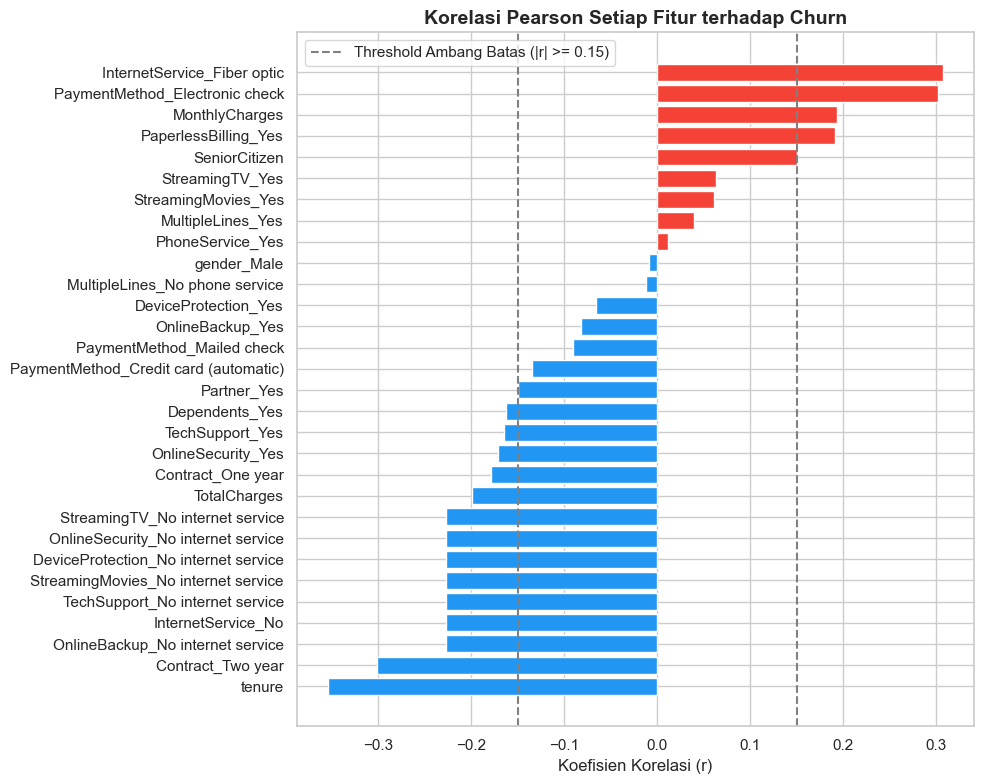

In [11]:
# Hitung korelasi Pearson setiap fitur terhadap Churn
korelasi = data_encoded.corr(method='pearson')['Churn'].sort_values()

# Hapus korelasi Churn terhadap dirinya sendiri
korelasi_fitur = korelasi.drop('Churn')

# Visualisasi Korelasi Pearson
plt.figure(figsize=(10, 8))
warna = ['#F44336' if val > 0 else '#2196F3' for val in korelasi_fitur.values]

plt.barh(korelasi_fitur.index, korelasi_fitur.values, color=warna)
plt.axvline(x=0.15, color='gray', linestyle='--', label='Threshold Ambang Batas (|r| >= 0.15)')
plt.axvline(x=-0.15, color='gray', linestyle='--')
plt.title('Korelasi Pearson Setiap Fitur terhadap Churn', fontsize=14, fontweight='bold')
plt.xlabel('Koefisien Korelasi (r)')
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
# Ambil fitur dengan nilai absolut korelasi >= 0.15
THRESHOLD = 0.15
fitur_terpilih = korelasi_fitur[korelasi_fitur.abs() >= THRESHOLD].index.tolist()

print(f'Ambang Batas Korelasi (|r| >= {THRESHOLD}):')
print(f'Jumlah fitur terpilih: {len(fitur_terpilih)} fitur\n')

tabel_korelasi = pd.DataFrame({
    'Fitur': fitur_terpilih,
    'Korelasi_r': korelasi_fitur[fitur_terpilih].values,
    'Korelasi_Absolut': korelasi_fitur[fitur_terpilih].abs().values
}).sort_values(by='Korelasi_Absolut', ascending=False).reset_index(drop=True)

display(tabel_korelasi.round(4))

# Fitur yang tereliminasi (korelasi sangat lemah, misal: gender, PhoneService)
fitur_dibuang = korelasi_fitur[korelasi_fitur.abs() < THRESHOLD].index.tolist()
print(f'Contoh fitur yang dieliminasi karena korelasi lemah (|r| < {THRESHOLD}):')
print(fitur_dibuang[:8])


Ambang Batas Korelasi (|r| >= 0.15):
Jumlah fitur terpilih: 19 fitur



,Fitur,Korelasi_r,Korelasi_Absolut
0,tenure,-0.3540,0.3540
1,InternetService_Fiber optic,0.3075,0.3075
2,Contract_Two year,-0.3016,0.3016
3,PaymentMethod_Electronic check,0.3015,0.3015
4,OnlineBackup_No internet service,-0.2276,0.2276
5,InternetService_No,-0.2276,0.2276
6,TechSupport_No internet service,-0.2276,0.2276
7,OnlineSecurity_No internet service,-0.2276,0.2276
8,StreamingTV_No internet service,-0.2276,0.2276
9,StreamingMovies_No internet service,-0.2276,0.2276


Contoh fitur yang dieliminasi karena korelasi lemah (|r| < 0.15):
['Partner_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'MultipleLines_No phone service', 'gender_Male', 'PhoneService_Yes']


### 3.4 Data Splitting (80% Train, 20% Test)


In [13]:
# Pisahkan variabel independen (X) dan dependen (y)
X = data_encoded[fitur_terpilih]
y = data_encoded['Churn']

# Split data secara stratified (menjaga proporsi Churn tetap seimbang di train & test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train_raw = X_train_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f'Total Data          : {len(data_encoded)}')
print(f'Data Training (80%) : {len(X_train_raw)} baris')
print(f'Data Testing  (20%) : {len(X_test_raw)} baris')


Total Data          : 7032
Data Training (80%) : 5625 baris
Data Testing  (20%) : 1407 baris


### 3.5 Normalisasi Min-Max
Normalisasi Min-Max mengubah rentang setiap fitur menjadi $[0, 1]$:
$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

*Penting:* Nilai minimum dan maksimum dihitung **hanya dari data training** untuk mencegah kebocoran data (*data leakage*), lalu diterapkan ke data testing.


In [14]:
# Hitung nilai minimum dan maksimum dari data training
nilai_min = X_train_raw.min()
nilai_max = X_train_raw.max()

# Fungsi normalisasi Min-Max sederhana
def normalisasi_minmax(df, min_val, max_val):
    return (df - min_val) / (max_val - min_val)

# Terapkan normalisasi ke data train dan test
X_train = normalisasi_minmax(X_train_raw, nilai_min, nilai_max)
X_test = normalisasi_minmax(X_test_raw, nilai_min, nilai_max)

print('Normalisasi Min-Max selesai!')
print('\nPreview 5 baris pertama data training ternormalisasi [0, 1]:')
display(X_train.head().round(4))


Normalisasi Min-Max selesai!

Preview 5 baris pertama data training ternormalisasi [0, 1]:


,tenure,Contract_Two year,OnlineBackup_No internet service,InternetService_No,TechSupport_No internet service,StreamingMovies_No internet service,DeviceProtection_No internet service,OnlineSecurity_No internet service,StreamingTV_No internet service,TotalCharges,Contract_One year,OnlineSecurity_Yes,TechSupport_Yes,Dependents_Yes,SeniorCitizen,PaperlessBilling_Yes,MonthlyCharges,PaymentMethod_Electronic check,InternetService_Fiber optic
0,0.9014,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.6993,0.0,1.0,1.0,1.0,0.0,0.0,0.7596,0.0,1.0
1,0.3521,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1158,0.0,0.0,1.0,0.0,0.0,0.0,0.1731,1.0,0.0
2,0.9437,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7245,0.0,0.0,1.0,0.0,0.0,0.0,0.7162,0.0,1.0
3,0.0282,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0250,0.0,0.0,0.0,0.0,0.0,0.0,0.6574,1.0,1.0
4,0.6761,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2368,0.0,1.0,0.0,0.0,0.0,0.0,0.2219,0.0,0.0


---
## FASE 4: Modeling - Algoritma K-Nearest Neighbors (KNN)

### 4.1 Konsep & Rumus Euclidean Distance
KNN mengklasifikasikan data uji berdasarkan mayoritas kelas dari $K$ tetangga terdekatnya. Jarak dihitung menggunakan jarak Euclidean:
$$d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

### 4.2 Eksperimen Berbagai Nilai $K \in \{3, 5, 7, 9\}$
Kita akan melatih model KNN untuk masing-masing nilai $K$ dan membandingkan performanya secara langsung.


In [15]:
# Eksperimen nilai K = 3, 5, 7, 9
daftar_k = [3, 5, 7, 9]
hasil_evaluasi = []
daftar_model = {}

for k in daftar_k:
    # 1. Inisialisasi dan latih model KNN
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train, y_train)
    daftar_model[k] = knn
    
    # 2. Prediksi data testing
    y_pred = knn.predict(X_test)
    
    # 3. Hitung metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    hasil_evaluasi.append({
        'K': k,
        'Akurasi (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2),
        'Model': knn,
        'y_pred': y_pred
    })
    print(f'Model KNN (K={k}) -> Akurasi: {acc*100:.2f}%, F1-Score: {f1*100:.2f}%')


Model KNN (K=3) -> Akurasi: 75.55%, F1-Score: 52.09%
Model KNN (K=5) -> Akurasi: 76.62%, F1-Score: 52.66%
Model KNN (K=7) -> Akurasi: 77.40%, F1-Score: 53.24%
Model KNN (K=9) -> Akurasi: 77.97%, F1-Score: 55.20%


---
## FASE 5: Evaluation & Analisis Perbandingan Nilai K

### 5.1 Tabel Ringkasan Performa $K = 3, 5, 7, 9$


In [16]:
# Tampilkan tabel perbandingan performa
df_hasil = pd.DataFrame(hasil_evaluasi).drop(columns=['Model', 'y_pred'])
print('='*60)
print('TABEL PERBANDINGAN PERFORMA KNN BERDASARKAN NILAI K')
print('='*60)
display(df_hasil)

# Menentukan K terbaik berdasarkan Akurasi & F1-Score
idx_terbaik = df_hasil['Akurasi (%)'].idxmax()
k_terbaik = int(df_hasil.loc[idx_terbaik, 'K'])
print(f'\nModel dengan performa Akurasi & F1-Score tertinggi diperoleh pada K = {k_terbaik}')


TABEL PERBANDINGAN PERFORMA KNN BERDASARKAN NILAI K


,K,Akurasi (%),Precision (%),Recall (%),F1-Score (%)
0,3,75.55,54.36,50.00,52.09
1,5,76.62,57.01,48.93,52.66
2,7,77.40,59.15,48.40,53.24
3,9,77.97,60.06,51.07,55.20



Model dengan performa Akurasi & F1-Score tertinggi diperoleh pada K = 9


### 5.2 Grafik Perbandingan Performa Nilai K


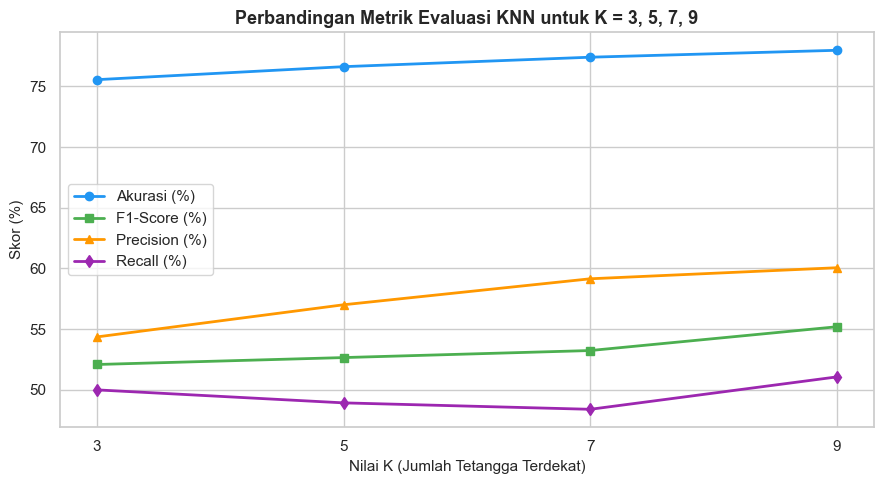

In [17]:
# Visualisasi Line Chart untuk melihat tren performa K
plt.figure(figsize=(9, 5))
plt.plot(df_hasil['K'], df_hasil['Akurasi (%)'], marker='o', linewidth=2, label='Akurasi (%)', color='#2196F3')
plt.plot(df_hasil['K'], df_hasil['F1-Score (%)'], marker='s', linewidth=2, label='F1-Score (%)', color='#4CAF50')
plt.plot(df_hasil['K'], df_hasil['Precision (%)'], marker='^', linewidth=2, label='Precision (%)', color='#FF9800')
plt.plot(df_hasil['K'], df_hasil['Recall (%)'], marker='d', linewidth=2, label='Recall (%)', color='#9C27B0')

plt.title('Perbandingan Metrik Evaluasi KNN untuk K = 3, 5, 7, 9', fontsize=13, fontweight='bold')
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)', fontsize=11)
plt.ylabel('Skor (%)', fontsize=11)
plt.xticks(daftar_k)
plt.legend()
plt.tight_layout()
plt.show()


### 5.3 Confusion Matrix Model Terbaik


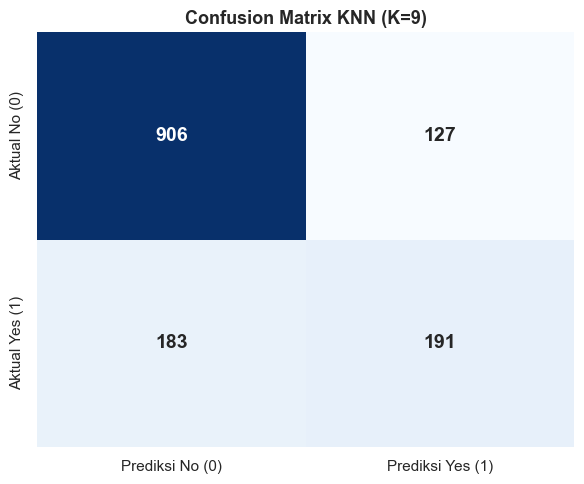

Rincian Confusion Matrix (K=9):
True Negative  (TN) : 906 (Pelanggan tidak churn, diprediksi benar)
False Positive (FP) : 127 (Pelanggan tidak churn, salah diprediksi churn)
False Negative (FN) : 183 (Pelanggan churn, salah diprediksi tidak churn)
True Positive  (TP) : 191 (Pelanggan churn, diprediksi benar)


In [18]:
# Ambil hasil prediksi model terbaik
item_terbaik = next(item for item in hasil_evaluasi if item['K'] == k_terbaik)
y_pred_terbaik = item_terbaik['y_pred']

cm = confusion_matrix(y_test, y_pred_terbaik)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Prediksi No (0)', 'Prediksi Yes (1)'],
            yticklabels=['Aktual No (0)', 'Aktual Yes (1)'],
            annot_kws={'size': 14, 'weight': 'bold'}, ax=ax)

ax.set_title(f'Confusion Matrix KNN (K={k_terbaik})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Rincian Confusion Matrix (K={k_terbaik}):')
print(f'True Negative  (TN) : {tn} (Pelanggan tidak churn, diprediksi benar)')
print(f'False Positive (FP) : {fp} (Pelanggan tidak churn, salah diprediksi churn)')
print(f'False Negative (FN) : {fn} (Pelanggan churn, salah diprediksi tidak churn)')
print(f'True Positive  (TP) : {tp} (Pelanggan churn, diprediksi benar)')


---
## FASE 6: Deployment & Prediksi Pelanggan Baru

### 6.1 Fungsi Prediksi Sederhana untuk Pelanggan Baru


In [19]:
# Ambil model terbaik yang sudah dilatih
model_terbaik = item_terbaik['Model']

def prediksi_churn_baru(data_input_dict):
    """
    Fungsi prediksi untuk pelanggan baru.
    Input berupa dictionary berisi nilai fitur terpilih.
    """
    df_baru = pd.DataFrame([data_input_dict])
    
    # Normalisasi data baru menggunakan min & max dari data training
    df_baru_norm = normalisasi_minmax(df_baru[fitur_terpilih], nilai_min, nilai_max)
    
    # Prediksi kelas dan probabilitas
    hasil = model_terbaik.predict(df_baru_norm)[0]
    prob = model_terbaik.predict_proba(df_baru_norm)[0][1]
    
    label = 'CHURN (Akan Berhenti)' if hasil == 1 else 'TETAP (Tidak Churn)'
    return label, prob

print('Fungsi prediksi_churn_baru() siap digunakan!')


Fungsi prediksi_churn_baru() siap digunakan!


In [20]:
# Contoh pengujian prediksi untuk 2 profil pelanggan berbeda:

# Profil A: Pelanggan baru (tenure rendah, fiber optic, month-to-month, electronic check)
pelanggan_A = {f: 0 for f in fitur_terpilih}
pelanggan_A.update({
    'tenure': 2,
    'MonthlyCharges': 95.5,
    'TotalCharges': 191.0,
    'InternetService_Fiber optic': 1,
    'PaymentMethod_Electronic check': 1,
    'PaperlessBilling_Yes': 1,
    'Contract_Two year': 0,
    'Contract_One year': 0
})

# Profil B: Pelanggan loyal (tenure tinggi, kontrak 2 tahun, bukan electronic check)
pelanggan_B = {f: 0 for f in fitur_terpilih}
pelanggan_B.update({
    'tenure': 60,
    'MonthlyCharges': 25.0,
    'TotalCharges': 1500.0,
    'InternetService_Fiber optic': 0,
    'PaymentMethod_Electronic check': 0,
    'PaperlessBilling_Yes': 0,
    'Contract_Two year': 1,
    'Contract_One year': 0
})

status_A, prob_A = prediksi_churn_baru(pelanggan_A)
status_B, prob_B = prediksi_churn_baru(pelanggan_B)

print('HASIL PREDIKSI PELANGGAN BARU:')
print('-'*50)
print(f'Pelanggan A : {status_A} | Probabilitas Churn: {prob_A*100:.1f}%')
print(f'Pelanggan B : {status_B} | Probabilitas Churn: {prob_B*100:.1f}%')


HASIL PREDIKSI PELANGGAN BARU:
--------------------------------------------------
Pelanggan A : CHURN (Akan Berhenti) | Probabilitas Churn: 88.9%
Pelanggan B : TETAP (Tidak Churn) | Probabilitas Churn: 11.1%
